# Сравнение матчеров на соседних кадрах трубы

Продолжение `romav2_pipes.ipynb`. Там RoMa v2 часто уходил в ложный режим «почти ноль»: сопоставлял неподвижные блики и пятна освещения, а не поверхность. Здесь проверяем, свойственно ли это только RoMa v2 или всем матчерам.

**Модели** (все без дообучения, обёртки в `matchers.py`):

| Модель | Тип | Откуда |
|---|---|---|
| RoMa v2 (`precise`) | плотная | `romav2` |
| RoMa v1 (outdoor) | плотная | `romatch` |
| RAFT large | плотная, оптический поток | `torchvision` |
| DINOv3 NN | взаимные ближайшие соседи по патчам того же DINOv3, что внутри RoMa v2 | `romav2` |
| LoFTR (outdoor) | полуплотная | `kornia` |
| DISK + LightGlue | разреженная | `kornia` |
| Шаблон (NCC) | классика, один глобальный сдвиг | OpenCV |

**Формат.** Каждая модель возвращает соответствия `kA → kB` в пикселях полосы трубы и уверенность. Плотные модели берём на сетке с шагом 8 px.

**Метрики на паре** (истинного потока нет, поэтому косвенные):
- `correct` — медианный сдвиг пары в пределах 60 px от ориентира (движение трубы);
- `zero` — медианный сдвиг в пределах 60 px от нуля (ложный режим);
- `inlier` — доля соответствий в пределах 30 px от ориентира;
- `cycle` — доля соответствий A→B, которые проход B→A возвращает с ошибкой меньше 5 px;
- `n`, `time` — число соответствий и время одного прохода.

Для `correct`, `zero` и `inlier` у всех моделей одинаковый бюджет: не больше 2000 самых уверенных соответствий. `cycle` считается на полном выводе.

In [1]:
import os, glob, sys, time
import certifi
os.environ.setdefault("SSL_CERT_FILE", certifi.where())

import numpy as np, cv2, torch, pandas as pd
import matplotlib.pyplot as plt
torch.set_float32_matmul_precision("highest")  # требование RoMa v2

sys.path.insert(0, ".")
import matchers as M
from romav2 import RoMaV2
from romav2.device import device
print("torch", torch.__version__, "| device:", device)
plt.rcParams["figure.dpi"] = 90

torch 2.15.0 | device: mps


## 1. Данные

Та же последовательность, тот же кадр и та же предобработка (`raw` и `flat`), что в `romav2_pipes.ipynb`.

In [2]:
SEQ = "../data/pipes/Данные 07 2026/14_эталон_1_выдержка_1600_gain_24_первая_хорошая"
files = sorted(glob.glob(os.path.join(SEQ, "*.jpg")))
I0, N = 1100, 40          # первый кадр и число соседних пар
TOP_N = 2000              # бюджет соответствий на пару

def read_rgb(i):
    return cv2.cvtColor(cv2.imread(files[i]), cv2.COLOR_BGR2RGB)

prof = cv2.cvtColor(read_rgb(I0), cv2.COLOR_RGB2GRAY).mean(1)
thr = prof[:300].mean() + 0.3 * (prof.max() - prof[:300].mean())
rows = np.where(prof > thr)[0]
Y0, Y1 = int(rows.min()) + 50, int(rows.max())

def stretch(a, p=99.5):
    a = a.astype(np.float32)
    return np.clip(a / np.percentile(a, p) * 255, 0, 255).astype(np.uint8)

flat_idx = range(I0 - 200, I0 + 200, 8)
FLAT = np.median(np.stack([read_rgb(i)[Y0:Y1].astype(np.float32) for i in flat_idx]), 0) + 1.0

def prep(i, mode="raw"):
    a = read_rgb(i)[Y0:Y1].astype(np.float32)
    if mode == "flat":
        a = a / FLAT
    return stretch(a)

print(len(files), "кадров; полоса трубы", (Y0, Y1), "→ размер входа", prep(I0).shape)

1995 кадров; полоса трубы (646, 3015) → размер входа (2369, 2000, 3)


## 2. Модели

In [3]:
v2 = RoMaV2()  # общий экземпляр: DINOv3 NN берёт его бэкбон
MATCHERS = [
    M.TemplateMatcher(),
    M.RoMaV2Matcher("precise", v2),
    M.RoMaV1Matcher(),
    M.RAFTMatcher(),
    M.DinoNNMatcher(v2),
    M.LoFTRMatcher(),
    M.DiskLightGlueMatcher(),
]
[m.name for m in MATCHERS]

Using cache found in /Users/feacs/.cache/torch/hub/facebookresearch_dinov3_adc254450203739c8149213a7a69d8d905b4fcfa


2026-11-15 19:43:27 INFO     romav2.romav2 - romav2:117 in __init__ - RoMa v2 initialized.

/Users/feacs/Desktop/study/nir-1/.venv/lib/python3.13/site-packages/romatch/models/model_zoo/roma_models.py:243: UserWarning: Local correlation is not supported on non-Linux platforms, setting use_custom_corr to False
  warnings.warn("Local correlation is not supported on non-Linux platforms, setting use_custom_corr to False")
2026-11-15 19:43:27.681 +03:00 | INFO     | romatch.models.model_zoo.roma_models:roma_model:255 - Using coarse resolution (560, 560), and upsample res (864, 864)


/Users/feacs/Desktop/study/nir-1/.venv/lib/python3.13/site-packages/romatch/models/model_zoo/roma_models.py:261: UserWarning: Local correlation is not supported on non-Linux platforms, setting use_custom_corr to False
  warnings.warn("Local correlation is not supported on non-Linux platforms, setting use_custom_corr to False")
/Users/feacs/Desktop/study/nir-1/.venv/lib/python3.13/site-packages/romatch/models/matcher.py:51: UserWarning: Local correlation is not supported on non-Linux platforms, setting use_custom_corr to False
  warn("Local correlation is not supported on non-Linux platforms, setting use_custom_corr to False")


['Template (NCC)',
 'RoMa v2 (precise)',
 'RoMa v1',
 'RAFT (1024)',
 'DINOv3 NN',
 'LoFTR (840)',
 'DISK+LightGlue']

## 3. Проверка обёрток на синтетическом сдвиге

Берём кадр и сдвигаем его на известные (+40, −120) px. Неподвижной составляющей тут нет, поэтому любая нормальная модель должна найти сдвиг. Если какая-то модель не справляется, ошибка в обёртке, а не в модели.

In [4]:
SYN = np.array([40.0, -120.0])
A0 = prep(I0, "raw")
As = A0[200:-200, 200:-200]
Bs = np.roll(np.roll(A0, int(SYN[1]), 0), int(SYN[0]), 1)[200:-200, 200:-200]
syn = []
for m in MATCHERS:
    ab, ba = M.run(m, As, Bs), M.run(m, Bs, As)
    syn.append(dict(method=m.name, **M.pair_metrics(M.top_n(ab, TOP_N), SYN, cycle=M.cycle_rate(ab, ba))))
pd.DataFrame(syn).set_index("method").round(3)

/Users/feacs/Desktop/study/nir-1/.venv/lib/python3.13/site-packages/romav2/features.py:140: UserWarning: CUDA is not available or torch_xla is imported. Disabling autocast.
  with torch.autocast(device_type="cuda", enabled=True, dtype=torch.bfloat16):


,n,dx,dy,inlier,correct,zero,cycle,time
method,,,,,,,,
Template (NCC),2000,40.000000,-120.000000,1.000,True,False,0.000,0.013
RoMa v2 (precise),2000,40.002998,-120.033997,1.000,True,False,0.924,2.991
RoMa v1,2000,39.945000,-119.896004,1.000,True,False,0.922,3.167
RAFT (1024),2000,40.055000,-120.071999,1.000,True,False,0.916,3.963
DINOv3 NN,1218,32.000000,-118.139999,0.591,True,False,1.000,0.441
LoFTR (840),2000,39.973999,-120.055000,1.000,True,False,0.591,0.443
DISK+LightGlue,2000,40.384998,-119.155998,1.000,True,False,1.000,0.573


## 4. Ориентир: движение трубы

Как в предыдущем ноутбуке, ориентир берём из шаблонного сопоставления: медиана его ответов по парам с высоким score. Ответы около нуля (артефакт неподвижной составляющей) отбрасываем.

In [5]:
tm = pd.DataFrame([M.pair_metrics(M.run(MATCHERS[0], prep(i, "flat"), prep(i + 1, "flat")), np.zeros(2))
                   | dict(score=float(M.run(MATCHERS[0], prep(i, "flat"), prep(i + 1, "flat"))["conf"][0]))
                   for i in range(I0, I0 + N)])
good = tm[(np.hypot(tm.dx, tm.dy) > 100) & (tm.score > tm.score.quantile(0.5))]
REF = np.array([good.dx.median(), good.dy.median()])
print("ориентир (dx, dy) =", REF, "| пар в выборке:", len(good))

ориентир (dx, dy) = [  56. -484.] | пар в выборке: 15


## 5. Прогон по последовательности

Для каждой пары `(i, i+1)`, каждой предобработки и каждой модели считаем оба направления. Занимает около получаса на MPS, поэтому результат сохраняем в `results/compare_pipes.csv`. При повторном запуске таблица читается из файла (для пересчёта удали его).

In [6]:
OUT = "results/compare_pipes.csv"
os.makedirs("results", exist_ok=True)
if os.path.exists(OUT):
    res = pd.read_csv(OUT)
else:
    rows = []
    for mode in ["raw", "flat"]:
        for i in range(I0, I0 + N):
            A, B = prep(i, mode), prep(i + 1, mode)
            for m in MATCHERS:
                ab, ba = M.run(m, A, B), M.run(m, B, A)
                rows.append(dict(method=m.name, mode=mode, i=i,
                                 **M.pair_metrics(M.top_n(ab, TOP_N), REF, cycle=M.cycle_rate(ab, ba))))
        print(mode, "готово")
    res = pd.DataFrame(rows)
    res.to_csv(OUT, index=False)
res.head()

/Users/feacs/Desktop/study/nir-1/.venv/lib/python3.13/site-packages/romav2/features.py:140: UserWarning: CUDA is not available or torch_xla is imported. Disabling autocast.
  with torch.autocast(device_type="cuda", enabled=True, dtype=torch.bfloat16):


raw готово


flat готово


,method,mode,i,n,dx,dy,inlier,correct,zero,cycle,time
0,Template (NCC),raw,1100,2000,56.000000,-484.000000,1.0,True,False,0.000000,0.008738
1,RoMa v2 (precise),raw,1100,2000,11.696411,-9.351440,0.0,False,True,0.114419,3.000368
2,RoMa v1,raw,1100,2000,2.743317,-2.992859,0.0,False,True,0.364824,2.850720
3,RAFT (1024),raw,1100,2000,-520.199585,-11.207397,0.0,False,False,0.000000,4.476269
4,DINOv3 NN,raw,1100,891,0.000000,0.000000,0.0,False,True,1.000000,0.478659


## 6. Сводная таблица

In [7]:
order = [m.name for m in MATCHERS]
summary = (res.groupby(["mode", "method"])
              .agg(correct=("correct", "mean"), zero=("zero", "mean"), inlier=("inlier", "mean"),
                   cycle=("cycle", "mean"), n=("n", "median"), time=("time", "median"))
              .reset_index())
summary["method"] = pd.Categorical(summary["method"], order)
summary = summary.sort_values(["mode", "method"]).set_index(["mode", "method"])
summary.style.format({"correct": "{:.0%}", "zero": "{:.0%}", "inlier": "{:.0%}", "cycle": "{:.0%}",
                      "n": "{:.0f}", "time": "{:.2f} c"})

Как читать:
- `correct` — главная метрика: в какой доле пар модель нашла настоящее движение трубы;
- `zero` — доля пар в ложном режиме; `correct + zero < 100 %` значит, что остальные пары ушли в случайный ответ;
- `inlier` — насколько соответствия согласованы внутри пары; высокий `correct` при низком `inlier` значит, что медиана верная, но много мусора;
- у шаблона `cycle` не определён, у RAFT уверенности нет, поэтому `top_n` для него берёт 2000 случайных точек сетки.

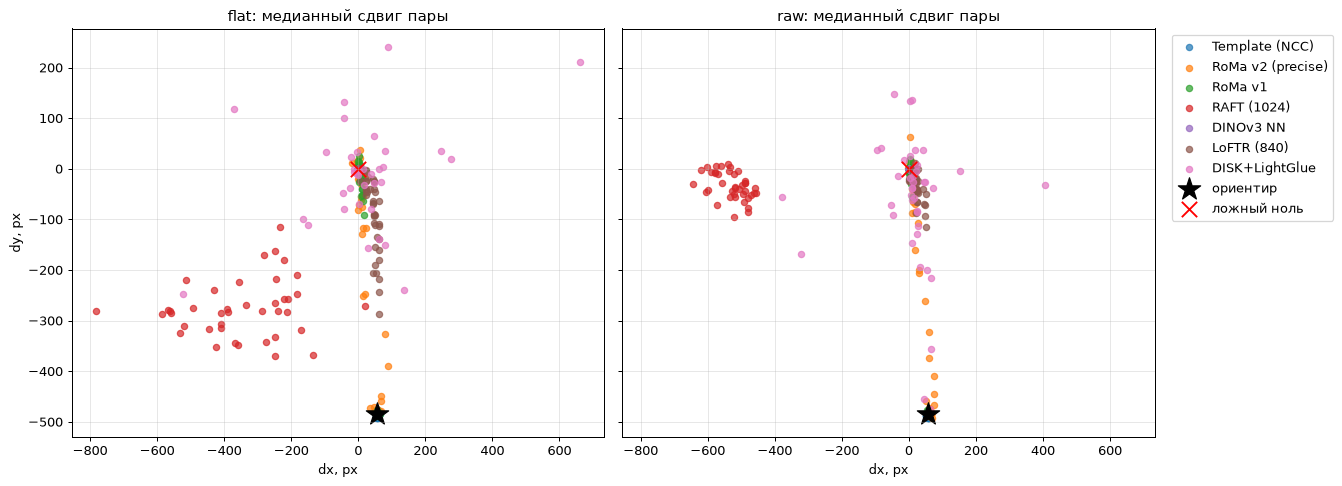

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5), sharex=True, sharey=True)
for a, (mode, g) in zip(ax, res.groupby("mode")):
    for name in order:
        gg = g[g.method == name]
        a.scatter(gg.dx, gg.dy, s=25, alpha=.7, label=name)
    a.scatter(*REF, marker="*", s=350, c="k", label="ориентир")
    a.scatter(0, 0, marker="x", s=150, c="r", label="ложный ноль")
    a.set_title(f"{mode}: медианный сдвиг пары"); a.set_xlabel("dx, px"); a.grid(alpha=.3)
ax[0].set_ylabel("dy, px"); ax[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

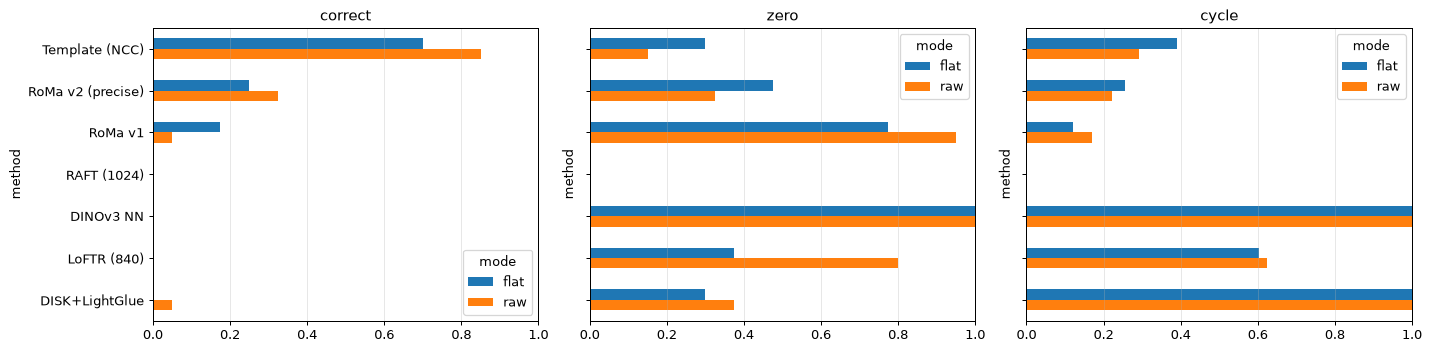

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
s = summary.reset_index()
for a, col in zip(ax, ["correct", "zero", "cycle"]):
    p = s.pivot(index="method", columns="mode", values=col).reindex(order)
    p.plot.barh(ax=a); a.set_title(col); a.set_xlim(0, 1); a.invert_yaxis(); a.grid(alpha=.3, axis="x")
    if a is not ax[0]: a.set_yticklabels([])
plt.tight_layout(); plt.show()

## 7. Как выглядят соответствия на одной паре

Стрелки: 150 самых уверенных соответствий каждой модели на паре `I0 → I0+1` (`flat`). Зелёные — в пределах 30 px от ориентира, красные — нет.

/Users/feacs/Desktop/study/nir-1/.venv/lib/python3.13/site-packages/romav2/features.py:140: UserWarning: CUDA is not available or torch_xla is imported. Disabling autocast.
  with torch.autocast(device_type="cuda", enabled=True, dtype=torch.bfloat16):


/var/folders/yp/z2jj_5n96rz1_t5yfx2vc4v80000gn/T/ipykernel_3360/3872806788.py:12: RuntimeWarning: Mean of empty slice
  a.set_title(f"{m.name}\n{ok.mean():.0%} у ориентира", fontsize=9); a.axis("off")
/Users/feacs/Desktop/study/nir-1/.venv/lib/python3.13/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


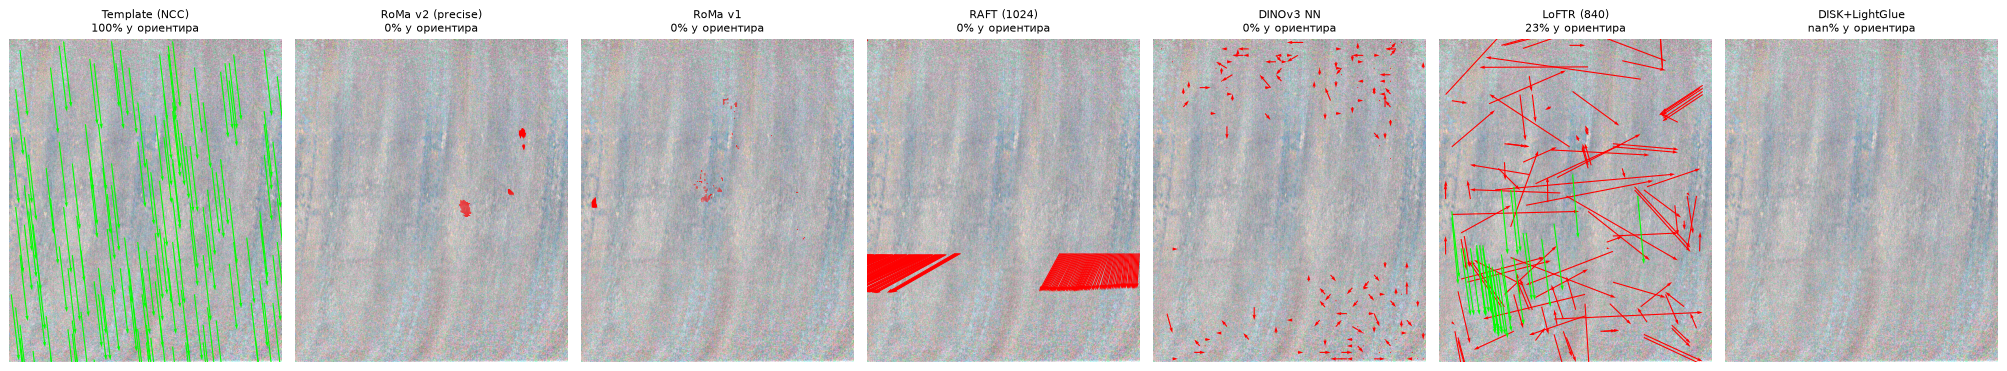

In [10]:
def show_matches(i=I0, mode="flat", k=150):
    A, B = prep(i, mode), prep(i + 1, mode)
    fig, ax = plt.subplots(1, len(MATCHERS), figsize=(3.2 * len(MATCHERS), 5))
    for a, m in zip(ax, MATCHERS):
        o = M.top_n(M.run(m, A, B), k)
        d = o["kB"] - o["kA"]
        ok = np.linalg.norm(d - REF, axis=1) < 30
        a.imshow(A, cmap="gray")
        for sel, c in [(~ok, "r"), (ok, "lime")]:
            a.quiver(o["kA"][sel, 0], o["kA"][sel, 1], d[sel, 0], -d[sel, 1], color=c,
                     angles="xy", scale_units="xy", scale=1, width=.004)
        a.set_title(f"{m.name}\n{ok.mean():.0%} у ориентира", fontsize=9); a.axis("off")
    plt.tight_layout(); plt.show()

show_matches()

## 8. Выводы

**Обёртки исправны.** На синтетическом сдвиге (+40, −120) все модели нашли верный сдвиг: медиана в пределах 1 px, `inlier` = 100 %. Исключение — DINOv3 NN с `inlier` 59 %, но это следствие шага патчей (вход сжимается до 800×800, патч 16 px → в исходных пикселях это ячейка ~32×39 px, грубее допуска 30 px), а не ошибка. Значит, всё, что ниже, — поведение самих моделей на реальных данных.

**Ориентир:** (dx, dy) = (56, −484) px за кадр, то есть сдвиг около 20 % высоты полосы. Для матчеров это большое смещение.

| | Template | RoMa v2 | RoMa v1 | RAFT | DINOv3 NN | LoFTR | DISK+LG |
|---|---|---|---|---|---|---|---|
| `correct` raw / flat | 85 / 70 % | **33 / 25 %** | 5 / 18 % | 0 / 0 % | 0 / 0 % | 0 / 0 % | 5 / 0 % |
| `zero` raw / flat | 15 / 30 % | 33 / 48 % | 95 / 78 % | 0 / 0 % | 100 / 100 % | 80 / 38 % | 38 / 30 % |
| прочее (случайный ответ) | 0 / 0 % | 35 / 28 % | 0 / 5 % | 100 / 100 % | 0 / 0 % | 20 / 63 % | 58 / 70 % |

1. **Ложный режим «почти ноль» есть не только у RoMa v2, а у всех обученных матчеров.** RoMa v1 уходит в него почти всегда (95 % пар на `raw`), LoFTR — в 80 %, DINOv3 NN — в 100 %. Из нейросетевых моделей RoMa v2 справляется лучше всех, хотя и он находит движение только в каждой третьей-четвёртой паре.
2. **Источник — признаки, а не головка RoMa.** Голые взаимные соседи по патчам DINOv3 (того же бэкбона, что внутри RoMa v2) дают нулевой сдвиг на всех 80 парах. В пространстве признаков неподвижная составляющая (блики, пятна освещения, виньетирование) похожа сильнее, чем текстура поверхности. Уточнение в RoMa v2 иногда вытаскивает верный режим, RoMa v1 — почти никогда.
3. **Flat-field помогает слабо и не всем.** У LoFTR доля ложного нуля падает с 80 до 38 %, у RoMa v1 — с 95 до 78 % (`correct` растёт с 5 до 18 %). Но освободившиеся пары уходят в случайный ответ, а не в верный. У RoMa v2 на `flat` стало даже хуже: 25 % против 33 %. Деление на медианный фон неподвижную составляющую до конца не убирает.
4. **RAFT и DISK+LightGlue здесь неприменимы.** RAFT ни разу не попал ни в ориентир, ни в ноль: сдвиг около 210 px в его масштабе 1024 больше, чем он умеет отслеживать. DISK+LightGlue находит всего 15–18 соответствий на пару (медиана), и их медиана случайна.
5. **Проверка цикла не отличает верный режим от ложного.** Наибольший `cycle` (100 %) — у DINOv3 NN и DISK+LightGlue, которые почти никогда не правы: нулевой сдвиг идеально согласован в обе стороны. Отсеивать ложный режим по `cycle` (и по уверенности самой модели) нельзя, нужен внешний критерий, например расстояние до нуля или до априорного сдвига.
6. **Когда RoMa попадает, соответствия чистые.** Максимальный `inlier` на паре — 96 % у RoMa v2 и 98 % у RoMa v1. Значит, проблема в выборе режима (глобального сопоставления), а не в точности уточнения.
7. **Шаблонное NCC остаётся самым надёжным** (85 % на `raw`), но сравнение для него нечестное: ориентир построен по его же ответам. Тем не менее это дешёвый (≈0,01 с) и достаточно надёжный источник грубого глобального сдвига.

**Время.** На синтетике (вход 1969×1600) проход занимал: RoMa v2 — 3,0 с, RoMa v1 — 3,2 с, RAFT (CPU) — 4,0 с, LoFTR, DINOv3 NN и DISK+LG — около 0,5 с, шаблон — 0,01 с. В прогоне по последовательности медианы в 5–10 раз больше, а отдельные проходы доходили до 1000 с. Похоже, машина засыпала или троттлила, поэтому колонку `time` в сводной таблице для абсолютных оценок использовать не стоит.

**Что делать дальше:**
- использовать шаблон как априорную оценку: сдвигать или обрезать B на найденный шаблоном сдвиг и отдавать RoMa v2 только уточнение (остаточный сдвиг будет мал, и ложный ноль станет совпадать с верным режимом);
- подавлять неподвижную составляющую сильнее: вычитать фон и брать high-pass вместо деления, маскировать блики;
- отбрасывать соответствия с |d| < 60 px или ограничивать поиск окном вокруг априорного сдвига;
- если этого не хватит, дообучить RoMa v2 на парах трубы с ориентиром из шаблона.